# NAGALA (Nhật Bản) — dự báo mắc đái tháo đường mới

Khác các notebook 01–09 (phân loại tình trạng **hiện tại**, nhãn tự khai hoặc cắt ngang), notebook này **dự báo mắc mới**: dùng các chỉ số đo ở thời điểm baseline để dự báo người chưa mắc có được chẩn đoán đái tháo đường trong thời gian theo dõi (trung vị khoảng 5 năm) hay không.

- Nguồn: bộ NAGALA, Okamura T. và cs., *Int J Obes* 2019;43:139–148, DOI 10.1038/s41366-018-0076-3; Dryad doi:10.5061/dryad.8q0p192; bản sao Zenodo 4996032. Giấy phép **CC0**.
- 15.464 người khám sức khoẻ định kỳ (Murakami Memorial Hospital, Gifu, Nhật Bản), 31 cột, nhãn `Incident DM 0/1` (373 ca dương, khoảng 2,4%).
- Hai phiên bản đặc trưng: **A** có glucose đói và HbA1c; **B** không có để thấy đóng góp của xét nghiệm đường huyết.
- Dữ liệu là người Nhật, nhóm đi khám sức khoẻ; **không phải người Việt**. Không dùng cho chẩn đoán/sàng lọc.

## 1. Thiết lập

In [1]:
EXPERIMENT = 'nagala'
PURPOSE = 'NAGALA: dự báo mắc đái tháo đường mới từ chỉ số baseline; so sánh có/không glucose đói + HbA1c.'
import os, json, hashlib, random, platform
from datetime import datetime, timezone
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, brier_score_loss, roc_curve, precision_recall_curve)
import torch
from torch import nn
from copy import deepcopy
import joblib
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'docker-compose.yml').exists()), None)
if ROOT is None: raise RuntimeError('Chạy notebook trong thư mục dự án.')
SMOKE = os.getenv('NOTEBOOK_SMOKE') == '1'  # Chỉ để kiểm thử kỹ thuật, không báo cáo kết quả.
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(1)
run_stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN_DIR = (Path('/tmp/duongan_notebook_smoke') if SMOKE else ROOT/'artifacts/notebook_runs') / EXPERIMENT / run_stamp
RUN_DIR.mkdir(parents=True, exist_ok=False)
print('Project:', ROOT, '| kết quả:', RUN_DIR, '| kiểm thử nhanh:', SMOKE)

Project: /Users/handq2212/DaiHoc/Nam4/LTHTTM/project | kết quả: /Users/handq2212/DaiHoc/Nam4/LTHTTM/project/artifacts/notebook_runs/nagala/20261112T081722_701428Z | kiểm thử nhanh: False


## 2. Tải, kiểm MD5 và đọc dữ liệu
File được tải về `data/raw/nagala/` (bị `.gitignore`), kiểm MD5 trước khi đọc. Tệp tải về là dữ liệu không tin cậy: chỉ đọc bằng `pandas.read_excel`, không thực thi gì từ tệp.

In [2]:
import urllib.request
URL = 'https://zenodo.org/records/4996032/files/Data%20set%20Int%20J%20Obesity.xlsx?download=1'
MD5 = '47edfb147078657a0eecfff7f9364532'
DATA_PATH = ROOT/'data/raw/nagala/nagala.xlsx'
def md5_of(path):
    h = hashlib.md5()
    with path.open('rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''): h.update(chunk)
    return h.hexdigest()
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(URL, DATA_PATH)
if md5_of(DATA_PATH) != MD5: raise ValueError('MD5 không khớp bản Zenodo/Dryad; dừng.')
print('MD5 khớp:', MD5)
raw = pd.read_excel(DATA_PATH)
print(raw.shape)
assert raw['Patient Number'].is_unique and not raw.duplicated().any()
print(raw.dtypes.to_string())

MD5 khớp: 47edfb147078657a0eecfff7f9364532


(15464, 31)
Patient Number                                                         int64
Sex, 1:Men, 2:Women                                                    int64
Baseline Age, yrs                                                      int64
Baseline Ethanol consumption g/wk                                    float64
Baseline Fatty liver 0/1                                               int64
Baseline BMI, kg/m2                                                  float64
Baseline Waist circumference(WC), cm                                 float64
Baseline WC≥90 in Men, ≥80 in Women 0/1                                int64
Baseline BMI≥25 0/1                                                    int64
Obesity phenotype 1-8                                                  int64
Follow up duration, days                                               int64
Baseline ALT, IU/L                                                     int64
Baseline AST, IU/L                                              

### Mô tả từng cột (31 cột) và quyết định sử dụng

| Cột | Ý nghĩa, đơn vị | Quyết định |
| --- | --- | --- |
| `Patient Number` | mã bệnh nhân | **Loại** (định danh; có thể phản ánh thứ tự ghi nhận) |
| `Sex, 1:Men, 2:Women` | giới; tiêu đề ghi 1/2 nhưng giá trị thật là 1 (nam, 8.430) và 0 (nữ, 7.034); khớp bài báo: 286 nam + 87 nữ mắc mới | Dùng, mã hoá lại `sex_male` (1 nam, 0 nữ) |
| `Baseline Age, yrs` | tuổi (năm) | Dùng |
| `Baseline Ethanol consumption g/wk` | rượu (g/tuần) | Dùng |
| `Baseline Fatty liver 0/1` | gan nhiễm mỡ (siêu âm) | Dùng |
| `Baseline BMI, kg/m2` | BMI | Dùng |
| `Baseline Waist circumference(WC), cm` | vòng eo (cm) | Dùng |
| `Baseline WC≥90 in Men, ≥80 in Women 0/1` | cờ suy ra từ vòng eo | Loại (dư thừa, suy ra từ cột gốc) |
| `Baseline BMI≥25 0/1` | cờ suy ra từ BMI | Loại (dư thừa) |
| `Obesity phenotype 1-8` | kiểu hình béo phì; giá trị thực gồm 0–8, 10, 11, 100, 101, 110, 111 (không khớp tiêu đề 1–8, có vẻ là mã nhị phân ghép) | Loại (suy ra từ BMI/vòng eo/gan nhiễm mỡ, mã không rõ) |
| `Follow up duration, days` | thời gian theo dõi (ngày) — **đo sau baseline, gắn với kết cục** | **Loại (rò rỉ)** |
| `Baseline ALT, IU/L` · `AST` · `GGT` | men gan (IU/L) | Dùng |
| `Baseline Body Weight, kg` | cân nặng (kg) | Loại (BMI đã chứa; trùng thông tin) |
| `Baseline Habit of exercise 0/1` | thói quen tập thể dục | Dùng |
| `Baseline HDL-cholesterol, mg/dL` | HDL (mg/dL); thiếu 11 dòng | Dùng (điền khuyết trên train) |
| `Baseline HDL-cholesterol, mmol/L` | cùng đại lượng, đơn vị khác; bằng 0 ở 11 dòng thiếu | Loại (trùng đơn vị) |
| `Baseline Total Cholesterol, mg/dL` / `mmol/L` | cholesterol toàn phần | Dùng mg/dL; loại mmol/L |
| `Baseline Triglycerides, mg/dL` / `mmol/L` | triglyceride | Dùng mg/dL; loại mmol/L |
| `Baseline HbA1c, %` / `mmol/mol` | HbA1c | Chỉ phiên bản **A**: dùng %; loại mmol/mol (trùng) |
| `Baseline Alcohol consumption, non:1…heavy:4` | nhóm mức uống rượu | Loại (suy ra từ g/tuần) |
| `Baseline Smoking status, 1:never, 2:past, 3:current` | hút thuốc | Dùng (one-hot) |
| `Baseline Fasting plasma glucose, mg/dl` / `mmol/L` | glucose huyết tương lúc đói | Chỉ phiên bản **A**: dùng mg/dL; loại mmol/L |
| `Baseline Systolic / Diastolic blood pressure, mmHg` | huyết áp | Dùng |
| `Incident DM 0/1` | **nhãn**: mắc mới trong thời gian theo dõi | Nhãn |

**Người đã mắc lúc baseline có nằm trong bộ này không?** Dữ liệu cho thấy không: baseline HbA1c tối đa 6,4% và glucose đói tối đa 109 mg/dL, dưới ngưỡng chẩn đoán (6,5% và 126 mg/dL). Bài báo gốc theo mô tả thứ cấp loại người có đái tháo đường hoặc glucose bất thường ở baseline, nhưng **tiêu chí loại trừ chính xác và tiêu chí chẩn đoán mắc mới chưa được xác minh từ toàn văn** (không đọc được). Nguồn thứ cấp cho rằng mắc mới là HbA1c ≥ 6,5%, glucose đói ≥ 7 mmol/L hoặc tự khai; nếu đúng, nhãn có thể cùng phép đo với đặc trưng glucose/HbA1c ở lần khám sau, nhưng thời điểm đo khác nhau nên không phải rò rỉ trực tiếp.

In [3]:
renames = {
 'Sex, 1:Men, 2:Women':'sex_male','Baseline Age, yrs':'age','Baseline Ethanol consumption g/wk':'ethanol_g_wk',
 'Baseline Fatty liver 0/1':'fatty_liver','Baseline BMI, kg/m2':'bmi','Baseline Waist circumference(WC), cm':'waist_cm',
 'Baseline ALT, IU/L':'alt','Baseline AST, IU/L':'ast','Baseline GGT, IU/L':'ggt','Baseline Habit of exercise 0/1':'exercise',
 'Baseline HDL-cholesterol, mg/dL':'hdl','Baseline Total Cholesterol, mg/dL':'total_chol','Baseline Triglycerides, mg/dL':'trig',
 'Baseline Smoking status, 1:never, 2:past, 3:current':'smoking','Baseline Systolic blood pressure, mmHg':'sbp',
 'Baseline Diastolic blood pressure, mmHg':'dbp','Baseline HbA1c, %':'hba1c','Baseline Fasting plasma glucose, mg/dl':'fpg',
 'Incident DM 0/1':'class'}
EXCLUDED = {
 'Patient Number':'định danh','Follow up duration, days':'đo sau baseline, gắn với kết cục (rò rỉ)',
 'Baseline WC≥90 in Men, ≥80 in Women 0/1':'suy ra từ vòng eo','Baseline BMI≥25 0/1':'suy ra từ BMI',
 'Obesity phenotype 1-8':'suy ra từ BMI/vòng eo/gan nhiễm mỡ, mã không rõ','Baseline Body Weight, kg':'trùng thông tin với BMI',
 'Baseline HDL-cholesterol, mmol/L':'trùng đơn vị','Baseline Total Cholesterol, mmol/L':'trùng đơn vị','Baseline Triglycerides, mmol/L':'trùng đơn vị',
 'Baseline HbA1c, mmol/mol':'trùng đơn vị (chỉ A dùng bản %)','Baseline Fasting plasma glucose, mmol/L':'trùng đơn vị (chỉ A dùng bản mg/dL)',
 'Baseline Alcohol consumption, non:1, light:2, moderate:3, heavy:4':'suy ra từ g/tuần'}
assert set(renames) | set(EXCLUDED) == set(raw.columns), set(raw.columns) ^ (set(renames) | set(EXCLUDED))
df = raw[list(renames)].rename(columns=renames).copy()
# Giá trị thật của giới là 1 (nam)/0 (nữ), không phải 1/2 như tiêu đề.
assert set(df.sex_male.unique()) == {0, 1}
df.loc[raw['Baseline HDL-cholesterol, mg/dL'].isna(), 'hdl'] = np.nan
assert df.hdl.isna().sum() == 11 and (raw.loc[df.hdl.isna(), 'Baseline HDL-cholesterol, mmol/L'] == 0).all()
print('Nhãn:', df['class'].value_counts().to_dict(), f"({df['class'].mean():.2%})")
print('Thiếu dữ liệu:', df.isna().sum()[lambda s: s > 0].to_dict())
LAB = ['fpg', 'hba1c']
BASE_NUM = ['age','ethanol_g_wk','bmi','waist_cm','alt','ast','ggt','hdl','total_chol','trig','sbp','dbp']
BASE_BIN = ['sex_male','fatty_liver','exercise']
BASE_CAT = ['smoking']
FEATURE_SETS = {'A_day_du': BASE_NUM + BASE_BIN + BASE_CAT + LAB, 'B_khong_glucose_hba1c': BASE_NUM + BASE_BIN + BASE_CAT}
FEATURE_DESCRIPTIONS = {'age':'Tuổi (năm)','ethanol_g_wk':'Rượu (g/tuần)','bmi':'BMI (kg/m²)','waist_cm':'Vòng eo (cm)','alt':'ALT (IU/L)',
 'ast':'AST (IU/L)','ggt':'GGT (IU/L)','hdl':'HDL (mg/dL)','total_chol':'Cholesterol toàn phần (mg/dL)','trig':'Triglyceride (mg/dL)',
 'sbp':'Huyết áp tâm thu (mmHg)','dbp':'Huyết áp tâm trương (mmHg)','sex_male':'Nam=1, nữ=0','fatty_liver':'Gan nhiễm mỡ 0/1',
 'exercise':'Thói quen tập thể dục 0/1','smoking':'Hút thuốc 1 chưa, 2 từng, 3 đang','fpg':'Glucose đói (mg/dL)','hba1c':'HbA1c (%)'}

Nhãn: {0: 15091, 1: 373} (2.41%)
Thiếu dữ liệu: {'hdl': 11}


## 3. Chia tập
Chia phân tầng theo nhãn 60/20/20 (train/validation/test) **trước** mọi phép fit. Tiền xử lý chỉ fit trên train. Với khoảng 373 ca dương, test chỉ có khoảng 75 ca dương nên khoảng bootstrap sẽ rộng.

In [4]:
idx = np.arange(len(df))
i_tr, i_tmp = train_test_split(idx, test_size=.4, stratify=df['class'], random_state=SEED)
i_va, i_te = train_test_split(i_tmp, test_size=.5, stratify=df['class'].iloc[i_tmp], random_state=SEED)
train, val, test = df.iloc[i_tr].copy(), df.iloc[i_va].copy(), df.iloc[i_te].copy()
assert not (set(i_tr) & set(i_va)) and not (set(i_tr) & set(i_te)) and not (set(i_va) & set(i_te))
for n, f in [('train', train), ('validation', val), ('test', test)]:
    print(f'{n}: {len(f)} mẫu, dương {int(f["class"].sum())} ({f["class"].mean():.2%})')

train: 9278 mẫu, dương 224 (2.41%)
validation: 3093 mẫu, dương 75 (2.42%)
test: 3093 mẫu, dương 74 (2.39%)


## 4. Phân tích dữ liệu train

Thống kê biến số trên train:
               count    mean    std     min     25%     50%     75%     max
age           9278.0   43.73   8.86   19.00   37.00   42.00   50.00   78.00
ethanol_g_wk  9278.0   48.02  82.51    0.00    0.00    1.00   66.00  413.00
bmi           9278.0   22.11   3.15   14.07   19.87   21.79   23.92   39.71
waist_cm      9278.0   76.44   9.15   36.90   69.80   76.00   82.50  123.40
alt           9278.0   20.02  15.31    2.00   13.00   17.00   23.00  856.00
ast           9278.0   18.40   9.36    3.00   14.00   17.00   21.00  590.00
ggt           9278.0   20.36  18.33    3.00   11.00   15.00   22.00  399.00
hdl           9274.0   56.41  15.58   16.70   45.00   54.40   65.90  173.60
total_chol    9278.0  197.79  33.37  100.00  174.00  196.00  219.00  475.00
trig          9278.0   81.09  59.01    7.00   44.00   65.00   99.00  910.00
sbp           9278.0  114.58  15.07   71.00  104.00  113.00  124.00  251.00
dbp           9278.0   71.64  10.61   39.00   64.50   71.00

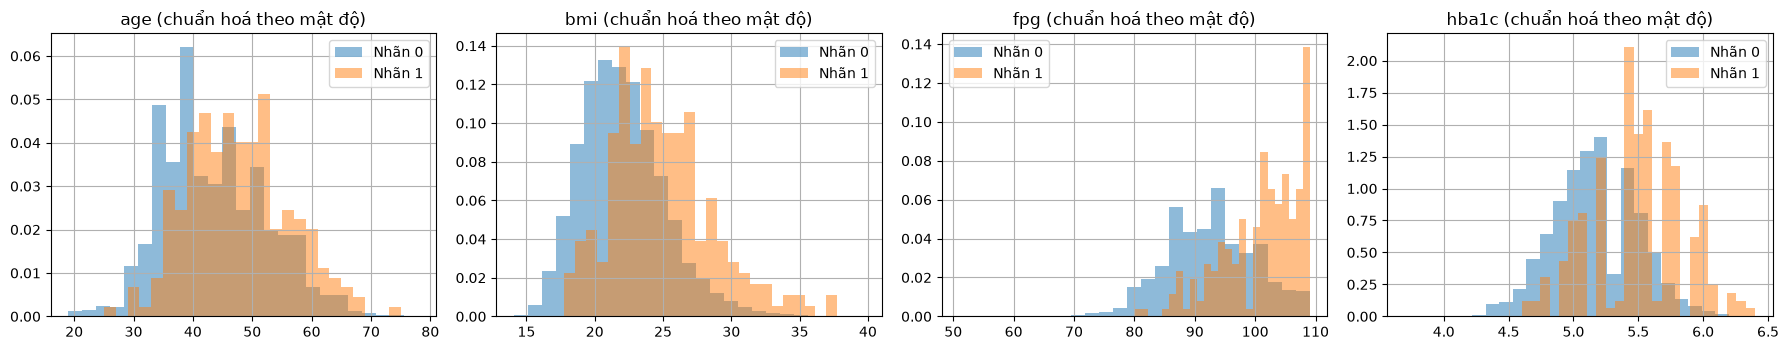

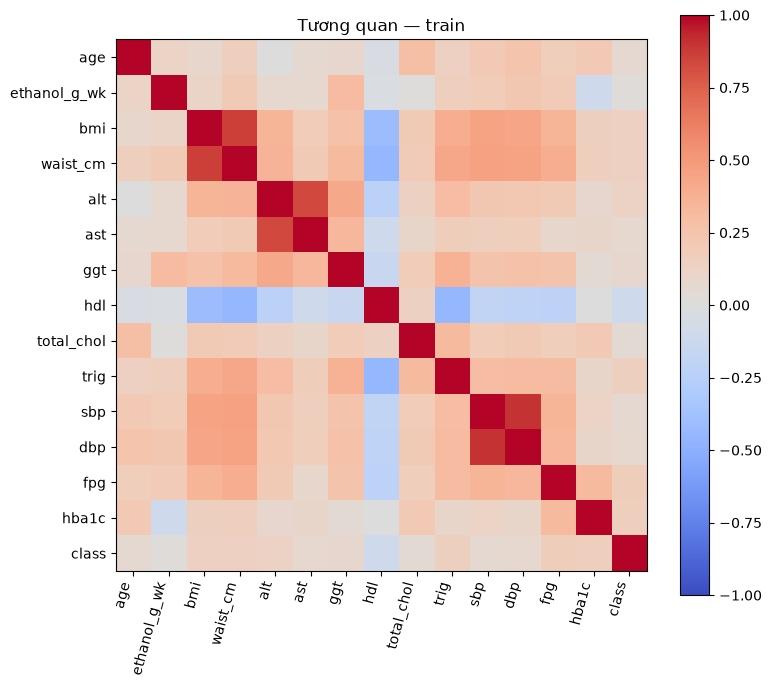

Tỷ lệ mắc mới theo HbA1c baseline (train):
              mean  sum  count
hba1c                         
(0.0, 5.3]  0.0100   62   6195
(5.3, 5.6]  0.0344   85   2473
(5.6, 5.9]  0.0987   52    527
(5.9, 6.2]  0.2821   22     78
(6.2, 6.5]  0.6000    3      5


In [5]:
print('Thống kê biến số trên train:'); print(train[BASE_NUM + LAB].describe().round(2).T.to_string())
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, col in zip(axes, ['age', 'bmi', 'fpg', 'hba1c']):
    for label in (0, 1): train.loc[train['class'] == label, col].hist(ax=ax, bins=25, alpha=.5, density=True, label=f'Nhãn {label}')
    ax.set_title(col + ' (chuẩn hoá theo mật độ)'); ax.legend()
plt.tight_layout(); plt.show()
corr = train[BASE_NUM + LAB + ['class']].corr()
fig, ax = plt.subplots(figsize=(8, 7)); im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr)), corr.columns, rotation=75, ha='right'); ax.set_yticks(range(len(corr)), corr.index)
ax.set_title('Tương quan — train'); fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()
print('Tỷ lệ mắc mới theo HbA1c baseline (train):')
print(train.groupby(pd.cut(train.hba1c, [0, 5.3, 5.6, 5.9, 6.2, 6.5]), observed=True)['class'].agg(['mean', 'sum', 'count']).round(4).to_string())

## 5. Mô hình, huấn luyện và lựa chọn
Quy trình như notebook 09: Dummy (prior), Logistic Regression, HistGradientBoosting và MLP chạy 3 seed (tối đa 200 epoch, tối thiểu 40, dừng sớm sau 25 epoch không cải thiện validation loss; loss có trọng số lớp dương). Chọn mô hình theo **ROC-AUC validation**, ngưỡng theo **F1 validation**; PR-AUC được báo cáo song song vì lớp dương hiếm. Hàm dưới chạy cho từng phiên bản đặc trưng, **chỉ tính validation**; test chạy một lần cho mô hình đã chọn của từng phiên bản ở mục 6.

[A_day_du] seed=42: epochs=40, best=11, val AUC=0.8918


[A_day_du] seed=43: epochs=40, best=9, val AUC=0.8821


[A_day_du] seed=44: epochs=40, best=8, val AUC=0.8882


[A_day_du] bảng validation (ngưỡng tham khảo 0.5):
                        roc_auc  pr_auc  precision  recall      f1
neural_seed_42           0.8918  0.2805     0.0927  0.8267  0.1667
neural_seed_44           0.8882  0.3003     0.0895  0.8667  0.1623
hist_gradient_boosting   0.8829  0.2334     0.1253  0.6533  0.2103
logistic_regression      0.8828  0.2491     0.0943  0.8400  0.1696
neural_seed_43           0.8821  0.2524     0.0892  0.8267  0.1610
dummy                    0.5000  0.0242     0.0000  0.0000  0.0000
[A_day_du] chọn: neural_seed_42 | ngưỡng F1 validation: 0.85


[B_khong_glucose_hba1c] seed=42: epochs=40, best=9, val AUC=0.8153


[B_khong_glucose_hba1c] seed=43: epochs=40, best=9, val AUC=0.8184


[B_khong_glucose_hba1c] seed=44: epochs=40, best=8, val AUC=0.8175


[B_khong_glucose_hba1c] bảng validation (ngưỡng tham khảo 0.5):
                        roc_auc  pr_auc  precision  recall      f1
logistic_regression      0.8218  0.1095     0.0700  0.6933  0.1271
neural_seed_43           0.8184  0.1200     0.0654  0.6800  0.1193
neural_seed_44           0.8175  0.1170     0.0655  0.7067  0.1199
neural_seed_42           0.8153  0.1066     0.0673  0.6667  0.1222
hist_gradient_boosting   0.7742  0.0844     0.0858  0.5467  0.1483
dummy                    0.5000  0.0242     0.0000  0.0000  0.0000
[B_khong_glucose_hba1c] chọn: logistic_regression | ngưỡng F1 validation: 0.8


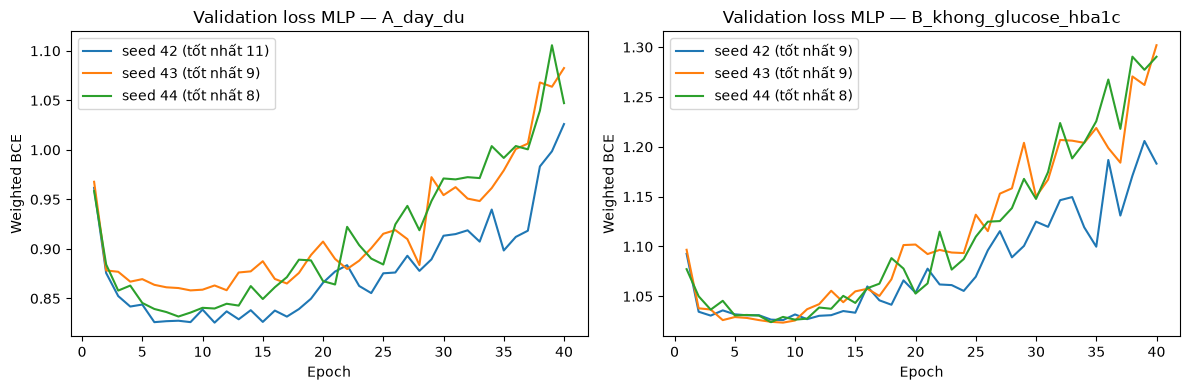

In [6]:
def make_preprocessor(feats):
    num = [c for c in feats if c not in BASE_CAT]
    cat = [c for c in feats if c in BASE_CAT]
    parts = [('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num)]
    if cat: parts.append(('cat', make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore')), cat))
    return ColumnTransformer(parts, sparse_threshold=0)

class Net(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n, 64), nn.ReLU(), nn.Dropout(.2), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x): return self.net(x).squeeze(-1)

seeds = [42] if SMOKE else [42, 43, 44]
max_epochs, min_epochs, patience_limit = (2, 1, 2) if SMOKE else (200, 40, 25)
batch_size = 128

def threshold_scores(y, s, t):
    p = (s >= t).astype(int)
    return {'roc_auc': float(roc_auc_score(y, s)), 'pr_auc': float(average_precision_score(y, s)),
            'precision': float(precision_score(y, p, zero_division=0)), 'recall': float(recall_score(y, p, zero_division=0)),
            'f1': float(f1_score(y, p, zero_division=0))}

def fit_version(name, feats):
    pre = make_preprocessor(feats)
    Xtr = pre.fit_transform(train[feats]).astype('float32'); Xva = pre.transform(val[feats]).astype('float32')
    ytr, yva = train['class'].to_numpy('float32'), val['class'].to_numpy('float32')
    cands = {'dummy': DummyClassifier(strategy='prior'),
             'logistic_regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED),
             'hist_gradient_boosting': HistGradientBoostingClassifier(max_iter=100 if not SMOKE else 5, max_leaf_nodes=15, learning_rate=.05,
                                                                       class_weight='balanced', random_state=SEED)}
    for n, e in cands.items(): e.fit(Xtr, ytr)
    xt, yt, xv, yv = map(torch.tensor, (Xtr, ytr, Xva, yva))
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([(len(ytr) - ytr.sum()) / ytr.sum()], dtype=torch.float32))
    runs = []
    for rs in seeds:
        torch.manual_seed(rs); random.seed(rs); np.random.seed(rs)
        m = Net(Xtr.shape[1]); opt = torch.optim.Adam(m.parameters(), lr=1e-3)
        loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(xt, yt), batch_size=batch_size, shuffle=True,
                                             generator=torch.Generator().manual_seed(rs))
        best, state, best_ep, pat, hist, upd = float('inf'), None, 0, 0, [], 0
        for ep in range(1, max_epochs + 1):
            m.train(); tot = 0.0
            for x, y in loader:
                opt.zero_grad(); l = loss_fn(m(x), y); l.backward(); opt.step(); tot += float(l.detach()) * len(y); upd += 1
            m.eval()
            with torch.no_grad(): vl = float(loss_fn(m(xv), yv))
            hist.append({'epoch': ep, 'train_loss': tot / len(ytr), 'val_loss': vl})
            if vl < best - 1e-4: best, best_ep, state, pat = vl, ep, deepcopy(m.state_dict()), 0
            else: pat += 1
            if ep >= min_epochs and pat >= patience_limit: break
        m.load_state_dict(state); m.eval()
        with torch.no_grad(): vs = torch.sigmoid(m(xv)).numpy()
        runs.append({'seed': rs, 'model': m, 'best_epoch': best_ep, 'epochs_run': len(hist), 'updates': upd,
                     'stopped_early': len(hist) < max_epochs, 'history': hist, 'val_scores': vs, 'val_auc': float(roc_auc_score(yva, vs))})
        print(f"[{name}] seed={rs}: epochs={len(hist)}, best={best_ep}, val AUC={runs[-1]['val_auc']:.4f}", flush=True)
    vsc = {n: e.predict_proba(Xva)[:, 1] for n, e in cands.items()}
    for r in runs: vsc[f"neural_seed_{r['seed']}"] = r['val_scores']
    table = pd.DataFrame({n: threshold_scores(yva, s, .5) for n, s in vsc.items()}).T.sort_values('roc_auc', ascending=False)
    selected = max(vsc, key=lambda n: roc_auc_score(yva, vsc[n]))   # hoà thì ưu tiên thứ tự khai báo (baseline đơn giản trước)
    grid = np.round(np.linspace(.05, .95, 19), 2)
    ttab = pd.DataFrame([{'threshold': float(t), **threshold_scores(yva, vsc[selected], t)} for t in grid])
    thr = float(ttab.loc[ttab.f1.idxmax(), 'threshold'])
    print(f'[{name}] bảng validation (ngưỡng tham khảo 0.5):'); print(table.round(4).to_string())
    print(f'[{name}] chọn: {selected} | ngưỡng F1 validation: {thr}')
    return dict(name=name, feats=feats, pre=pre, cands=cands, runs=runs, vsc=vsc, table=table, selected=selected, thr=thr, ttab=ttab)

versions = {k: fit_version(k, v) for k, v in FEATURE_SETS.items()}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (k, v) in zip(axes, versions.items()):
    for r in v['runs']:
        c = pd.DataFrame(r['history']); ax.plot(c.epoch, c.val_loss, label=f"seed {r['seed']} (tốt nhất {r['best_epoch']})")
    ax.set_title(f'Validation loss MLP — {k}'); ax.set_xlabel('Epoch'); ax.set_ylabel('Weighted BCE'); ax.legend()
plt.tight_layout(); plt.show()

## 6. Đánh giá test (một lần cho mô hình đã chọn mỗi phiên bản)
Chỉ số: ROC-AUC, **PR-AUC** (chỉ số chính; đường cơ sở ngẫu nhiên bằng tỷ lệ dương ≈ 2,4%), precision/recall/F1 tại ngưỡng chọn trên validation, Brier, biểu đồ reliability và bootstrap phân tầng 95%. Vì mô hình dùng `class_weight='balanced'`/`pos_weight`, điểm thô bị đẩy lên so với xác suất thật nên Brier thô kém; ta còn hiệu chỉnh logistic (Platt) **fit trên validation**, áp lên test, rồi báo Brier và reliability sau hiệu chỉnh. Ngưỡng và ROC/PR không đổi (hiệu chỉnh đơn điệu).

In [7]:
def scores_for(v, frame, which):
    X = v['pre'].transform(frame[v['feats']]).astype('float32')
    if which.startswith('neural_seed_'):
        r = next(r for r in v['runs'] if which == f"neural_seed_{r['seed']}")
        r['model'].eval()
        with torch.no_grad(): return torch.sigmoid(r['model'](torch.tensor(X))).numpy()
    return v['cands'][which].predict_proba(X)[:, 1]

def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p)).reshape(-1, 1)

yva, yte = val['class'].to_numpy(), test['class'].to_numpy()
results, test_scores_all = {}, {}
rng = np.random.default_rng(SEED)
neg, pos = np.flatnonzero(yte == 0), np.flatnonzero(yte == 1)
boot_idx = [np.concatenate([rng.choice(neg, len(neg)), rng.choice(pos, len(pos))]) for _ in range(20 if SMOKE else 1000)]
for k, v in versions.items():
    sel, thr = v['selected'], v['thr']
    s_te = scores_for(v, test, sel); s_va = v['vsc'][sel]
    platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(s_va), yva)       # hiệu chỉnh fit trên validation
    p_te = platt.predict_proba(logit(s_te))[:, 1]
    pred = (s_te >= thr).astype(int)
    m = {**threshold_scores(yte, s_te, thr), 'accuracy': float(accuracy_score(yte, pred)),
         'brier_raw': float(brier_score_loss(yte, s_te)), 'brier_calibrated': float(brier_score_loss(yte, p_te)),
         'brier_prior_only': float(brier_score_loss(yte, np.full(len(yte), yva.mean()))),
         'pr_auc_random_baseline': float(yte.mean()),
         'confusion_matrix': confusion_matrix(yte, pred, labels=[0, 1]).tolist()}
    keys = {'roc_auc': lambda ix: roc_auc_score(yte[ix], s_te[ix]), 'pr_auc': lambda ix: average_precision_score(yte[ix], s_te[ix]),
            'recall': lambda ix: recall_score(yte[ix], pred[ix]), 'precision': lambda ix: precision_score(yte[ix], pred[ix], zero_division=0),
            'brier_calibrated': lambda ix: brier_score_loss(yte[ix], p_te[ix])}
    ci = {n: np.quantile([f(ix) for ix in boot_idx], [.025, .975]).tolist() for n, f in keys.items()}
    results[k] = {'selected': sel, 'threshold': thr, 'test': m, 'bootstrap_95': ci, 'n_test': int(len(yte)), 'positives_test': int(yte.sum())}
    test_scores_all[k] = (s_te, p_te)
    print(f'=== {k}: {sel}, ngưỡng {thr} ==='); print(json.dumps({'test': m, 'bootstrap_95': ci}, indent=1))
summary = pd.DataFrame({k: {'mô hình': r['selected'], 'ROC-AUC': r['test']['roc_auc'], 'PR-AUC': r['test']['pr_auc'],
    'precision': r['test']['precision'], 'recall': r['test']['recall'], 'F1': r['test']['f1'], 'Brier (hiệu chỉnh)': r['test']['brier_calibrated'],
    'Brier (chỉ tỷ lệ nền)': r['test']['brier_prior_only']} for k, r in results.items()}).T
print(summary.round(4).to_string())

=== A_day_du: neural_seed_42, ngưỡng 0.85 ===
{
 "test": {
  "roc_auc": 0.8636383982525088,
  "pr_auc": 0.23604270066994526,
  "precision": 0.22033898305084745,
  "recall": 0.527027027027027,
  "f1": 0.3107569721115538,
  "accuracy": 0.9440672486259295,
  "brier_raw": 0.1334161013364792,
  "brier_calibrated": 0.02046840824186802,
  "brier_prior_only": 0.023352691208802578,
  "pr_auc_random_baseline": 0.02392499191723246,
  "confusion_matrix": [
   [
    2881,
    138
   ],
   [
    35,
    39
   ]
  ]
 },
 "bootstrap_95": {
  "roc_auc": [
   0.8127296267781529,
   0.9068590369103784
  ],
  "pr_auc": [
   0.17085510545195778,
   0.3340867501223282
  ],
  "recall": [
   0.4189189189189189,
   0.6351351351351351
  ],
  "precision": [
   0.17552214809472294,
   0.2658959537572254
  ],
  "brier_calibrated": [
   0.019295355025678872,
   0.02155355387367308
  ]
 }
}


=== B_khong_glucose_hba1c: logistic_regression, ngưỡng 0.8 ===
{
 "test": {
  "roc_auc": 0.8084832099406463,
  "pr_auc": 0.08478609973930512,
  "precision": 0.09444444444444444,
  "recall": 0.22972972972972974,
  "f1": 0.13385826771653545,
  "accuracy": 0.9288716456514711,
  "brier_raw": 0.16406501829624176,
  "brier_calibrated": 0.022790350019931793,
  "brier_prior_only": 0.023352691208802578,
  "pr_auc_random_baseline": 0.02392499191723246,
  "confusion_matrix": [
   [
    2856,
    163
   ],
   [
    57,
    17
   ]
  ]
 },
 "bootstrap_95": {
  "roc_auc": [
   0.7631190523083534,
   0.853667649928829
  ],
  "pr_auc": [
   0.06679539132520036,
   0.12101922664308928
  ],
  "recall": [
   0.13513513513513514,
   0.32432432432432434
  ],
  "precision": [
   0.05668799953666165,
   0.1309035153328347
  ],
  "brier_calibrated": [
   0.02220165324397385,
   0.02332911887206137
  ]
 }
}
                                   mô hình   ROC-AUC    PR-AUC precision    recall        F1 Brier (hiệu

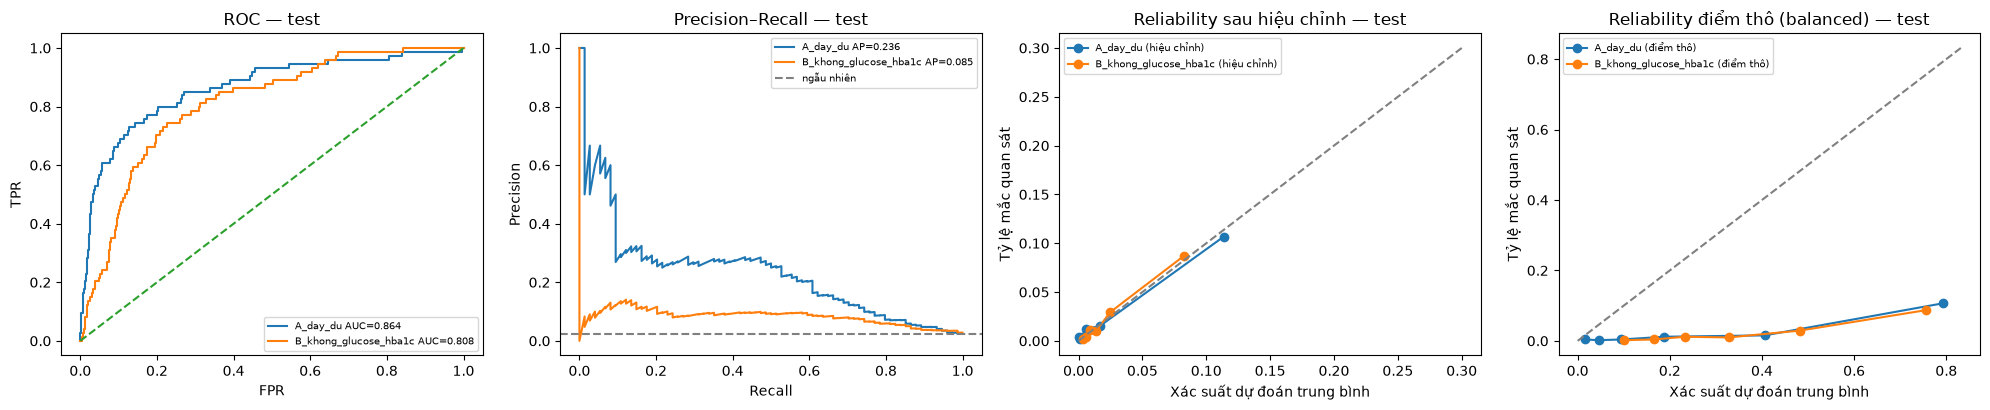

Mỗi nhóm reliability có rất ít ca dương (test khoảng 75 ca dương / 6 nhóm), nên các điểm nhiễu; chỉ đọc như xu hướng.


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
for k, (s, p) in test_scores_all.items():
    fpr, tpr, _ = roc_curve(yte, s); pr, rc, _ = precision_recall_curve(yte, s)
    axes[0].plot(fpr, tpr, label=f"{k} AUC={results[k]['test']['roc_auc']:.3f}")
    axes[1].plot(rc, pr, label=f"{k} AP={results[k]['test']['pr_auc']:.3f}")
    fr, mp = calibration_curve(yte, p, n_bins=6, strategy='quantile')
    axes[2].plot(mp, fr, 'o-', label=f'{k} (hiệu chỉnh)')
    fr, mp = calibration_curve(yte, s, n_bins=6, strategy='quantile')
    axes[3].plot(mp, fr, 'o-', label=f'{k} (điểm thô)')
axes[0].plot([0, 1], [0, 1], '--'); axes[0].set(xlabel='FPR', ylabel='TPR', title='ROC — test')
axes[1].axhline(yte.mean(), ls='--', color='gray', label='ngẫu nhiên'); axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–Recall — test')
for ax, t in zip(axes[2:], ['Reliability sau hiệu chỉnh — test', 'Reliability điểm thô (balanced) — test']):
    ax.plot([0, max(.3, ax.get_xlim()[1])], [0, max(.3, ax.get_xlim()[1])], '--', color='gray'); ax.set(xlabel='Xác suất dự đoán trung bình', ylabel='Tỷ lệ mắc quan sát', title=t)
for ax in axes: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print('Mỗi nhóm reliability có rất ít ca dương (test khoảng 75 ca dương / 6 nhóm), nên các điểm nhiễu; chỉ đọc như xu hướng.')

## 7. Độ quan trọng đặc trưng (permutation importance, validation)

A_day_du: ROC-AUC validation gốc 0.8918
fpg            0.0716
hba1c          0.0662
age            0.0179
trig           0.0103
smoking        0.0087
bmi            0.0063
fatty_liver    0.0054
hdl            0.0038
total_chol     0.0035
sex_male       0.0034


B_khong_glucose_hba1c: ROC-AUC validation gốc 0.8218
age             0.0522
bmi             0.0381
fatty_liver     0.0240
alt             0.0180
hdl             0.0139
dbp             0.0116
trig            0.0113
smoking         0.0110
ethanol_g_wk    0.0049
ast             0.0007


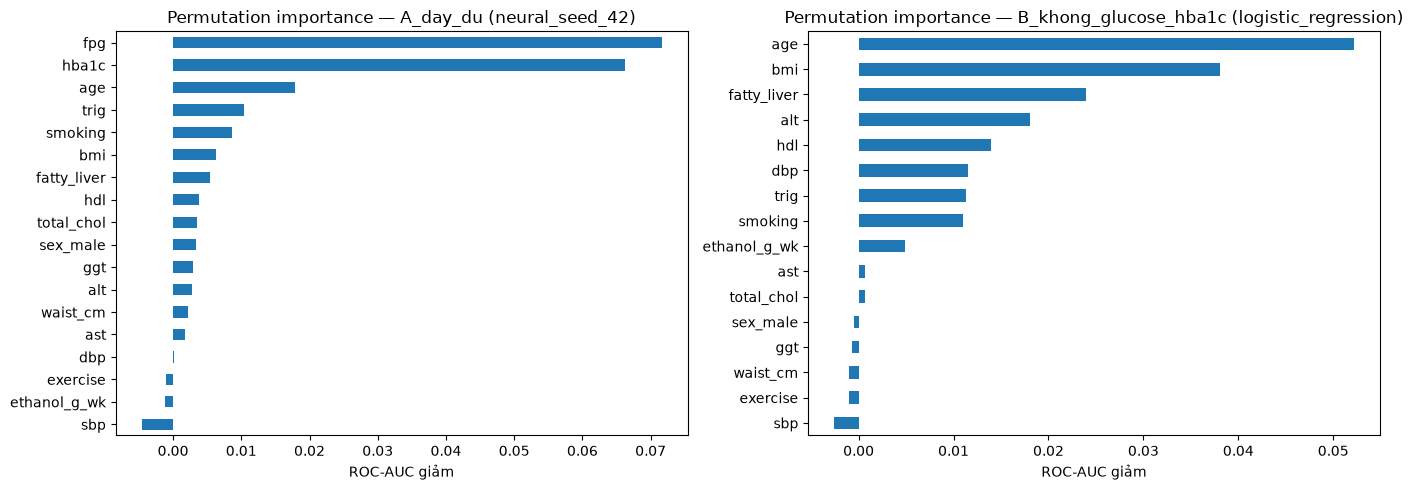

In [9]:
def perm_importance(v, repeats=1 if SMOKE else 10):
    sel = v['selected']; base = roc_auc_score(yva, scores_for(v, val, sel)); r = np.random.default_rng(SEED); out = {}
    for col in v['feats']:
        d = []
        for _ in range(repeats):
            sh = val.copy(); sh[col] = r.permutation(sh[col].to_numpy())
            d.append(base - roc_auc_score(yva, scores_for(v, sh, sel)))
        out[col] = float(np.mean(d))
    return base, dict(sorted(out.items(), key=lambda kv: kv[1], reverse=True))
importance = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (k, v) in zip(axes, versions.items()):
    base, imp = perm_importance(v); importance[k] = imp
    print(f'{k}: ROC-AUC validation gốc {base:.4f}'); print(pd.Series(imp).round(4).head(10).to_string())
    pd.Series(imp).iloc[::-1].plot.barh(ax=ax, title=f'Permutation importance — {k} ({v["selected"]})'); ax.set_xlabel('ROC-AUC giảm')
plt.tight_layout(); plt.show()

## 8. Lưu kết quả

In [10]:
def sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''): h.update(chunk)
    return h.hexdigest()
report = {'experiment': EXPERIMENT, 'purpose': PURPOSE, 'smoke_test': SMOKE,
 'source': {'url': URL, 'doi': '10.5061/dryad.8q0p192', 'paper': 'Okamura et al., Int J Obes 2019;43:139-148, 10.1038/s41366-018-0076-3', 'license': 'CC0',
            'md5': MD5, 'sha256': sha256(DATA_PATH)},
 'excluded_columns': EXCLUDED, 'feature_sets': FEATURE_SETS, 'feature_descriptions': FEATURE_DESCRIPTIONS,
 'split': {'scheme': 'stratified 60/20/20 by label, random_state=42', 'train': len(train), 'validation': len(val), 'test': len(test),
           'positives': {'train': int(train['class'].sum()), 'validation': int(val['class'].sum()), 'test': int(test['class'].sum())}},
 'training_config': {'seeds': seeds, 'max_epochs': max_epochs, 'min_epochs': min_epochs, 'patience': patience_limit, 'batch_size': batch_size, 'learning_rate': .001},
 'selection_rule': 'highest validation ROC-AUC (ties favor baseline order); threshold = max F1 on validation; Platt calibration fit on validation',
 'versions': {k: {'validation_metrics': v['table'].to_dict(orient='index'), 'selected_model': v['selected'], 'selected_threshold': v['thr'],
                  'neural_runs': [{x: r[x] for x in ['seed', 'best_epoch', 'epochs_run', 'updates', 'stopped_early', 'val_auc']} for r in v['runs']],
                  **results[k], 'permutation_importance_validation': importance[k]} for k, v in versions.items()},
 'libraries': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'sklearn': sklearn.__version__, 'torch': torch.__version__},
 'warning': 'Retrospective experiment on Japanese health-check cohort; not Vietnamese, not clinical validation. Label criteria not verified from full paper text.'}
(RUN_DIR/'report.json').write_text(json.dumps(report, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')
for k, v in versions.items():
    joblib.dump(v['pre'], RUN_DIR/f'preprocessor_{k}.joblib')
    for n, e in v['cands'].items(): joblib.dump(e, RUN_DIR/f'{k}__{n}.joblib')
    for r in v['runs']: torch.save({'state_dict': r['model'].state_dict(), 'seed': r['seed']}, RUN_DIR/f"{k}__neural_seed_{r['seed']}.pt")
print('Lưu artifact:', RUN_DIR)

Lưu artifact: /Users/handq2212/DaiHoc/Nam4/LTHTTM/project/artifacts/notebook_runs/nagala/20261112T081722_701428Z


## 9. Diễn giải và giới hạn
- Chỉ phiên bản A so với B cho biết xét nghiệm glucose đói/HbA1c đóng góp bao nhiêu vào dự báo; xem bảng ở mục 6 và permutation importance ở mục 7.
- Test chỉ có khoảng 75 ca dương; khoảng bootstrap rộng và chỉ mô tả điều kiện theo mẫu test. Test được dùng một lần mỗi phiên bản; các phép so sánh A/B không dùng test để chọn.
- Dân số Nhật Bản, người đi khám sức khoẻ định kỳ một bệnh viện, tuổi 18–79: **không phải người Việt**; hiệu chỉnh và ngưỡng không chuyển được sang dân số khác.
- Tiêu chí loại trừ lúc baseline và tiêu chí chẩn đoán mắc mới **chưa được xác minh từ toàn văn bài báo**. Thời gian theo dõi khác nhau giữa các người (164–4.732 ngày) nhưng nhãn là nhị phân, bỏ qua điều này (không phân tích sống còn); `Follow up duration` đã loại để tránh rò rỉ.
- Không có validation ngoài độc lập, không dùng cho chẩn đoán/sàng lọc.